# QMSS5074GR: Projects in Advanced Machine Learning
## Project 2: CNN & Transfer Learning for Medical Image Classification

---

### Group Information

Fill this in before you submit.

**Group number:** 1

| Full Name | UNI |
|-----------|-----|
|  Yingqi Huan  |  YH3755   |

**Public GitHub repository URL:** https://github.com/kikiyqhuan/QMSS5074GR-Projects-in-Advanced-Machine-Learning.git

## How to Complete and Submit This Project

**Due: Monday, November 16, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_2.ipynb`.

### 1. Get started

This project runs in **Google Colab**, which gives you a free GPU for training. The project folder contains the notebook:

```
Fall2026_QMSS5074GR_Project_2/
└── Project_2.ipynb
```

The dataset is too large to include in the folder, so it is shared through Google Drive (step 3 below). There is nothing else to download.

1. Unzip the project folder. Then go to [colab.research.google.com](https://colab.research.google.com), sign in with your **Columbia (LionMail) Google account**, choose **File → Upload notebook**, and select `Project_2.ipynb`.
2. Check that a GPU is on: **Runtime → Change runtime type → T4 GPU**.
3. Add the dataset to your Google Drive (you only need to do this once):
   1. Open the [shared dataset folder](https://drive.google.com/drive/folders/18O-BnGOIw9ZiUwy17Uk_361xyfTF-qAN?usp=sharing) while signed in with your Columbia account.
   2. Right-click **`COVID-19_Radiography_Dataset.zip`** and choose **Organize → Add shortcut**.
   3. Choose **All locations → My Drive → Add**.

   ![Step 1: Right-click the zip file, then Organize, then Add shortcut](https://github.com/user-attachments/assets/6515aa71-484b-4364-ac44-2331477720e8)

   ![Step 2: Choose All locations, then My Drive, then Add](https://github.com/user-attachments/assets/0d0d8f6c-a868-49c4-9e38-54f3006af39b)

4. Run the cells in **Section 0** in order. They connect to your Drive, unzip the dataset, and prepare the data you will use for every model.

**Working in Colab:**

- Colab saves your notebook in your Google Drive, in the **Colab Notebooks** folder.
- If your session disconnects, the unzipped data and trained models are lost. Run Section 0 again to continue.
- If you run out of memory, delete models you no longer need with `del model_name` and `tf.keras.backend.clear_session()`, or use the optional save and reload cells at the end of Section 0.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Runtime → Restart session and run all**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible. Training several models takes time, so leave enough time for this final run.
- Fill in the **Group Information** cell at the top, including your GitHub link.
- Download the notebook with **File → Download → Download .ipynb**.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 2 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_2` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_2/
    └── Project_2.ipynb
```

Do **not** upload the dataset, saved data files, or saved models to GitHub. They are too large (GitHub rejects files over 100 MB).

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart session and run all finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` is in `Project_2/` in your public group repository

## About the Project

### What this project is about

Chest X-rays are one of the fastest and cheapest ways to examine the lungs, and they were widely used to screen patients during the COVID-19 pandemic. Reading them takes trained radiologists, who are often in short supply. Can a deep learning model learn to tell COVID-19, viral pneumonia, and healthy lungs apart from an X-ray image?

In this project, you will build a complete deep learning pipeline for **medical image classification**. You will train a convolutional neural network (CNN) from scratch as a baseline, apply **transfer learning** with ResNet, try three more architectures of your choice, test data augmentation, and compare every model on the same test set. Finally, you will reflect on which model works best, why, and how it could be useful in the real world.

> The models in this project are for learning purposes only. They are not suitable for diagnosing patients.

### The prediction task

This is a **multi-class image classification** problem with **three classes**:

**COVID-19 · Normal · Viral Pneumonia**

Each model takes a chest X-ray image as input and outputs the probability of each class.

### The data

The images come from the **COVID-19 Radiography Database**, created by researchers from Qatar University, the University of Dhaka, and their collaborators. It collects chest X-rays from several public sources into one dataset.

> **Citation:** M.E.H. Chowdhury, T. Rahman, A. Khandakar, R. Mazhar, M.A. Kadir, Z.B. Mahbub, K.R. Islam, M.S. Khan, A. Iqbal, N. Al-Emadi, M.B.I. Reaz, "Can AI help in screening Viral and COVID-19 pneumonia?" arXiv preprint, 29 March 2020. [https://arxiv.org/abs/2003.13145](https://arxiv.org/abs/2003.13145)

The dataset is organized into one folder per class. This project uses three of them:

| Class | Folder | Images in the dataset | Images used in this project |
|-------|--------|----------------------:|----------------------------:|
| COVID-19 | `COVID/images` | 3,616 | 1,345 |
| Normal | `Normal/images` | 10,192 | 1,345 |
| Viral Pneumonia | `Viral Pneumonia/images` | 1,345 | 1,345 |

The dataset also contains a fourth class (`Lung_Opacity`) and lung masks for each image (`masks` folders). This project does not use them.

### How the data is prepared

Section 0 prepares the data for you, so that every model uses exactly the same inputs:

- **Equal-sized classes:** A random sample of 1,345 images is taken from each class, the size of the smallest class. This keeps the data small enough for Colab's memory, and it also balances the classes. You will discuss this choice in Section 1.
- **Image format:** Each image is resized to **192 × 192** pixels, stored with **3 color channels** (so that pre-trained models such as ResNet can use it), and scaled to values between **0 and 1**.
- **Fixed split:** The data is split into **training (64%)**, **validation (16%)**, and **test (20%)** sets, with the same class proportions in each. Use these same splits for every model so that your comparisons are fair.

---

## 0. Setup and Data Loading

Run these cells in order. This code is provided, so you don't need to change it. When you finish this section, you will have `X_train`, `X_val`, `X_test` (images) and `y_train`, `y_val`, `y_test` (one-hot encoded labels).

### Connect to Google Drive

In [1]:
# Connect to Google Drive. A pop-up will ask you to sign in: use your Columbia account.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Unzip the Dataset

In [2]:
# Unzip the dataset into this Colab session (takes 1–2 minutes; skipped if it is already unzipped)
import os
import glob
import zipfile

drive_folder = '/content/drive/MyDrive'
zip_path = os.path.join(drive_folder, 'COVID-19_Radiography_Dataset.zip')

if not os.path.exists(zip_path):
    # Also look one folder down, in case the shortcut was added inside a folder
    matches = glob.glob(os.path.join(drive_folder, '*', 'COVID-19_Radiography_Dataset.zip'))
    if not matches:
        raise FileNotFoundError(
            "Couldn't find COVID-19_Radiography_Dataset.zip in your Google Drive. "
            "Follow step 3 of 'How to Complete and Submit This Project' to add the shortcut to My Drive.")
    zip_path = matches[0]

if not os.path.isdir('COVID-19_Radiography_Dataset'):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('.')

print('Dataset ready:', sorted(os.listdir('COVID-19_Radiography_Dataset')))

Dataset ready: ['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


### Import Libraries

In [3]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Dense, Dropout, Flatten,
                                     BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.applications import ResNet50, VGG19, InceptionV3

# Fix random seeds so results are as repeatable as possible
keras.utils.set_random_seed(42)

print('TensorFlow version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None found. Turn it on with Runtime → Change runtime type → T4 GPU.')

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Collect Image File Paths

In [4]:
base_path = 'COVID-19_Radiography_Dataset'
categories = ['COVID/images', 'Normal/images', 'Viral Pneumonia/images']
class_names = ['COVID', 'NORMAL', 'PNEUMONIA']

# One list of file paths per class
fnames = []
for category in categories:
    image_folder = os.path.join(base_path, category)
    file_names = sorted(os.listdir(image_folder))
    fnames.append([os.path.join(image_folder, f) for f in file_names])

# Keep the full counts: you will need them in Section 1
original_counts = dict(zip(class_names, [len(f) for f in fnames]))
print('Number of images in each class (full dataset):', original_counts)

Number of images in each class (full dataset): {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}


### Sample an Equal Number of Images per Class

In [5]:
# Take a random sample from each class, the size of the smallest class.
# This keeps the data small enough for Colab's memory and balances the classes.
n_per_class = min(len(f) for f in fnames)

rng = random.Random(42)
fnames = [sorted(rng.sample(f, n_per_class)) for f in fnames]

print('Images per class used in this project:', n_per_class)

Images per class used in this project: 1345


### Preprocess the Images

In [6]:
IMG_SIZE = 192

def preprocessor(img_path):
    """Load one image, convert it to 3-channel RGB, resize it, and scale pixel values to 0–1."""
    img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype=np.float32) / 255.0

# Try it on one image
preprocessor(fnames[0][0]).shape

(192, 192, 3)

In [7]:
# Load and preprocess every image (takes about a minute)
image_filepaths = fnames[0] + fnames[1] + fnames[2]

X = np.empty((len(image_filepaths), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
for i, path in enumerate(image_filepaths):
    X[i] = preprocessor(path)

print('X shape:', X.shape)          # (number of images, height, width, channels)
print('Pixel range:', X.min(), 'to', X.max())

X shape: (4035, 192, 192, 3)
Pixel range: 0.0 to 1.0


### Create the Labels

In [8]:
# The images were loaded class by class, so the labels follow the same order
y_labels = np.repeat(class_names, n_per_class)

# One-hot encode the labels for Keras (one column per class)
y = pd.get_dummies(y_labels).astype('float32')
y

,COVID,NORMAL,PNEUMONIA
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
4030,0.0,0.0,1.0
4031,0.0,0.0,1.0
4032,0.0,0.0,1.0
4033,0.0,0.0,1.0


### Look at Sample Images

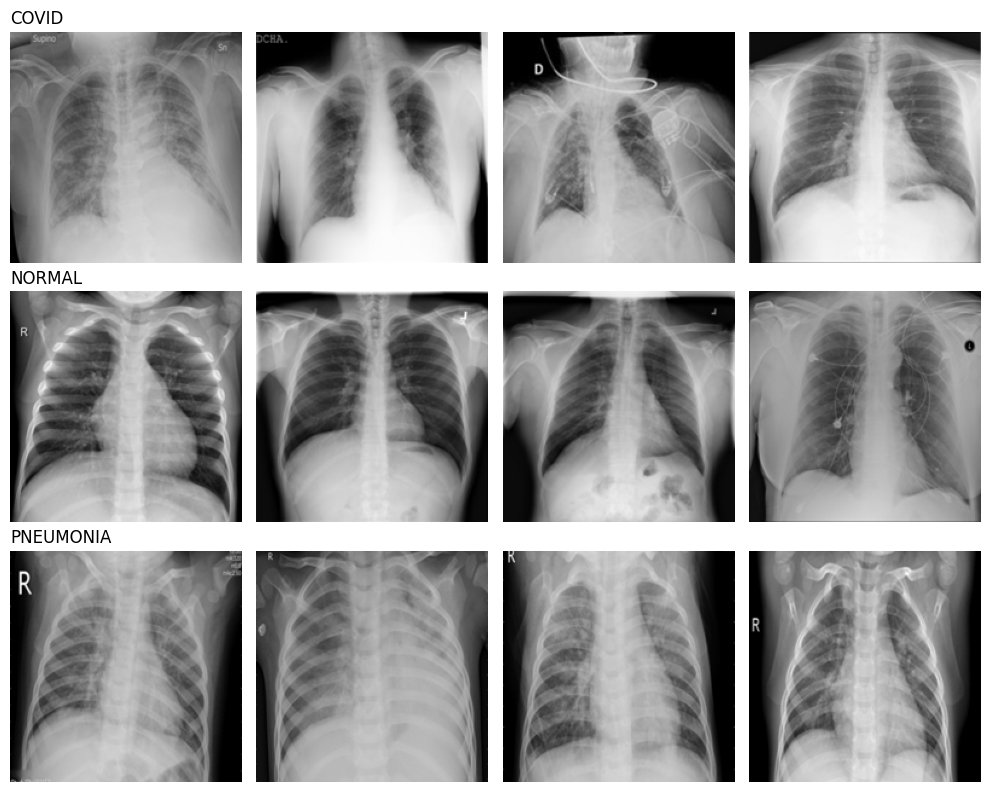

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for row, (name, files) in enumerate(zip(class_names, fnames)):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(preprocessor(files[col]))
        ax.axis('off')
        if col == 0:
            ax.set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Split into Training, Validation, and Test Sets

In [9]:
# 20% test set, then 20% of the remaining data as a validation set (64% / 16% / 20% overall)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
del X  # free memory

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
del X_train_full, y_train_full  # free memory

print('Training:  ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:      ', X_test.shape, y_test.shape)

Training:   (2582, 192, 192, 3) (2582, 3)
Validation: (646, 192, 192, 3) (646, 3)
Test:       (807, 192, 192, 3) (807, 3)


### Optional: Save and Reload the Prepared Data

If Colab runs out of memory, use **Runtime → Restart session** and run the reload cell below instead of all of Section 0 (run the **Import Libraries** cell first). The saved files are stored in this Colab session only, so they are lost if the session disconnects.

In [10]:
# Save the prepared data (optional)
for name, arr in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test),
                  ('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    np.save(f'{name}.npy', np.asarray(arr))

In [ ]:
# Reload the prepared data (optional)
X_train, X_val, X_test = (np.load(f'{name}.npy') for name in ['X_train', 'X_val', 'X_test'])
y_train, y_val, y_test = (pd.DataFrame(np.load(f'{name}.npy'), columns=class_names)
                          for name in ['y_train', 'y_val', 'y_test'])

---

## 1. Dataset and Exploratory Data Analysis

### Describe the Dataset

Describe the dataset using basic statistics and sample images. For example, show the number of images per class in each split, the image dimensions, pixel intensity statistics, and several sample images from each class.

,Train,Validation,Test,Total
COVID,860,216,269,1345
NORMAL,861,215,269,1345
PNEUMONIA,861,215,269,1345
Total,2582,646,807,4035


Original image size: (299, 299)
Preprocessed image size: (192, 192, 3)
COVID: mean=0.544, std=0.244, min=0.000, max=1.000, std of image means=0.101
NORMAL: mean=0.504, std=0.259, min=0.000, max=1.000, std of image means=0.085
PNEUMONIA: mean=0.491, std=0.247, min=0.000, max=1.000, std of image means=0.075


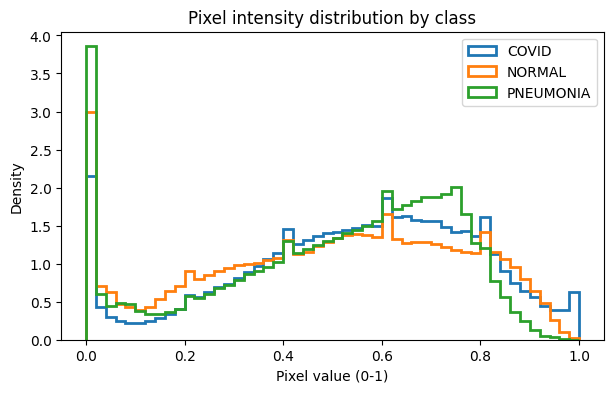

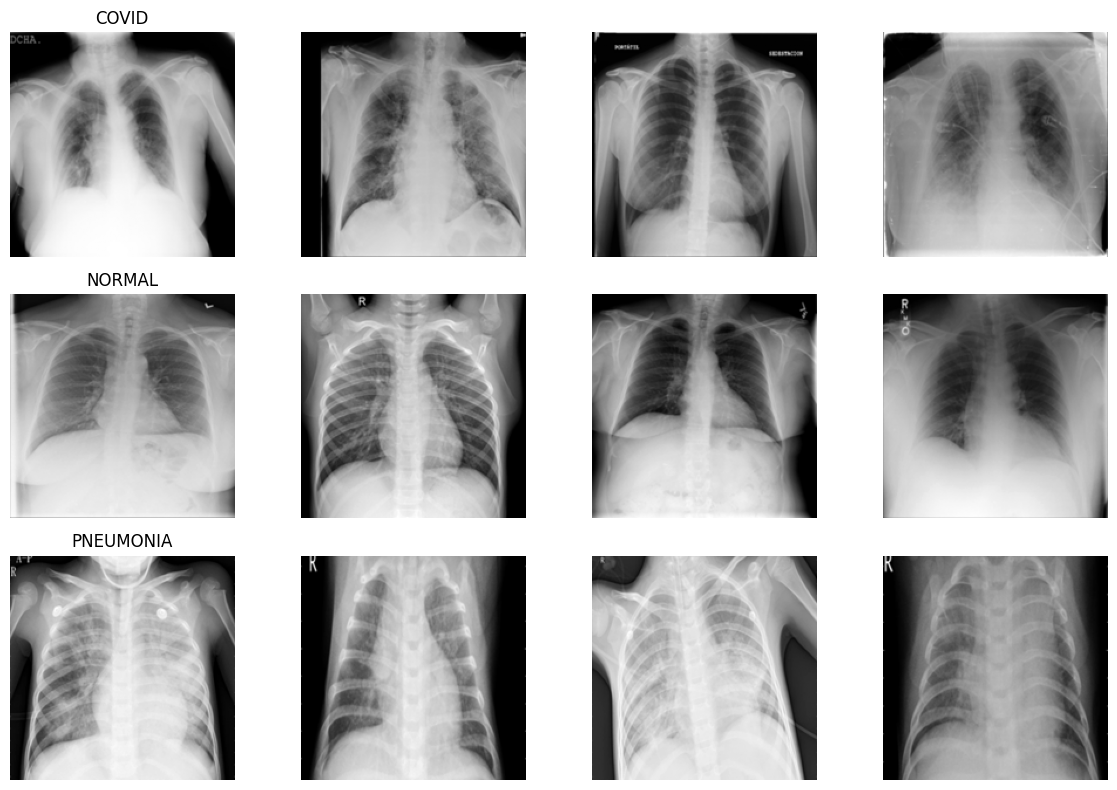

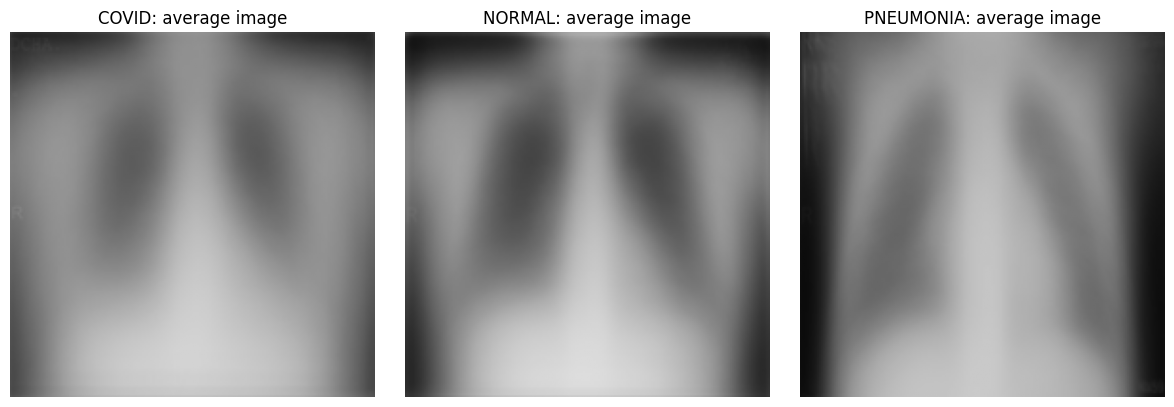

In [11]:
# 1. Number of images per class in each split
counts = pd.DataFrame({'Train': y_train.sum(),
                       'Validation': y_val.sum(),
                       'Test': y_test.sum()}).astype(int)
counts['Total'] = counts.sum(axis=1)          # add a column with the total of each class
counts.loc['Total'] = counts.sum()            # add a row with the total of each split
display(counts)

# 2. Image dimensions
print('Original image size:', Image.open(fnames[0][0]).size)
print('Preprocessed image size:', X_train.shape[1:])

# 3. Pixel intensity statistics per class
labels = y_train.values.argmax(axis=1)
for i, name in enumerate(class_names):
    gray = X_train[labels == i, :, :, 0]      # one channel is enough (all 3 are identical)
    img_means = gray.mean(axis=(1, 2))        # average brightness of each image
    print(f'{name}: mean={gray.mean():.3f}, std={gray.std():.3f}, '
          f'min={gray.min():.3f}, max={gray.max():.3f}, '
          f'std of image means={img_means.std():.3f}')

plt.figure(figsize=(7, 4))
for i, name in enumerate(class_names):
    gray = X_train[labels == i, :, :, 0]
    plt.hist(gray[::10].ravel(), bins=50, density=True, histtype='step', linewidth=2, label=name)
plt.xlabel('Pixel value (0-1)')
plt.ylabel('Density')
plt.title('Pixel intensity distribution by class')
plt.legend()
plt.show()

# 4. Sample images from each class
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for i, name in enumerate(class_names):
    idx = np.where(labels == i)[0][:4]
    for j, k in enumerate(idx):
        axes[i, j].imshow(X_train[k, :, :, 0], cmap='gray')
        axes[i, j].axis('off')
    axes[i, 0].set_title(name)
plt.tight_layout()
plt.show()

# 5. Average image of each class
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, name in enumerate(class_names):
    mean_img = X_train[labels == i, :, :, 0].mean(axis=0)
    axes[i].imshow(mean_img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(f'{name}: average image')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

Describe what you observe. How do the three classes look different, and how might that help or challenge a model?

Each split is balanced: about 861 training, 215 validation and 269 test images per class (2,582 / 646 / 807 in total). The original images are 299 * 299 grayscale PNGs; Section 0 resizes them to 192 * 192, copies the gray channel into 3 channels, and scales the pixels to 0-1.

The classes look different. Normal lungs are dark and clear. COVID-19 images are the brightest on average (mean pixel value 0.544, vs 0.504 for Normal and 0.491 for viral pneumonia), because infected lungs look hazier and whiter. COVID images also vary the most in brightness from image to image (std of image means 0.101), probably because they come from many different sources. Viral pneumonia images come from a children's dataset, so the chest looks smaller, which is easy to see in the average images.

These differences should make the task fairly easy for a CNN. The risk is that the model learns shortcuts, such as child vs. adult or which hospital an image came from, instead of the actual lung findings. COVID-19 and viral pneumonia can also look similar, so I expect some mistakes between those two classes.

### Class Balance

The full dataset is **imbalanced**, but Section 0 uses the same number of images from each class. Using `original_counts`, plot the number of images per class in the full dataset next to the number used in this project.

,Full dataset,Used in this project,Share of full (%)
COVID,3616,1345,23.9
NORMAL,10192,1345,67.3
PNEUMONIA,1345,1345,8.9


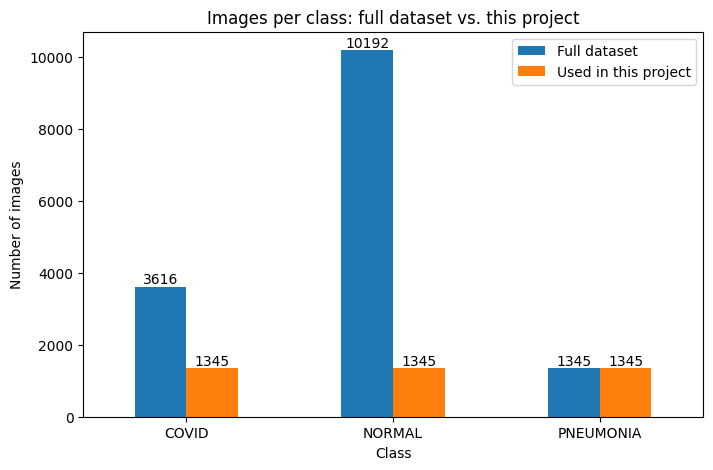

In [12]:
# Full dataset vs. the balanced sample
balance = pd.DataFrame({'Full dataset': original_counts,
                        'Used in this project': {name: n_per_class for name in class_names}})
balance['Share of full (%)'] = (100 * balance['Full dataset'] / balance['Full dataset'].sum()).round(1)
display(balance)

ax = balance[['Full dataset', 'Used in this project']].plot(kind='bar', rot=0, figsize=(8, 5))
for bars in ax.containers:
    ax.bar_label(bars)
ax.set(title='Images per class: full dataset vs. this project',
       xlabel='Class', ylabel='Number of images')
plt.show()

Answer the following:

1. How imbalanced is the full dataset?
2. Common strategies for imbalanced data include **class weighting**, **oversampling**, **undersampling**, and **augmentation**. Which of these does Section 0 use, and why do you think it was chosen?
3. If you trained on all the images instead, which strategy would you use? How would you expect it to change model performance?

1. Quite imbalanced. Normal has 10,192 images (67.3%), COVID-19 has 3,616 (23.9%), and Viral Pneumonia has 1,345 (8.9%). The largest class is about 7.6 times the smallest, so a model that always predicted “Normal” would already reach about 67.3% accuracy.

2. Random undersampling: each class is reduced to a random sample of 1,345 images, the size of the smallest class. It keeps the data small enough for Colab’s memory, makes training faster, and gives perfectly balanced classes. The cost is that most Normal and COVID images are thrown away.

3. I would use class weighting together with data augmentation. Class weighting keeps every image and makes errors on small classes cost more. Augmentation adds variety to the small Viral Pneumonia class without simply repeating images. Because the test set would also be imbalanced, I would evaluate with macro-F1 and recall, not just accuracy.

### Practical Value

Reflect on the practical value of this classification task. Who might benefit from a model like this in a real-world setting?

I think this model could help doctors, but it should not replace them. During an outbreak, hospitals get more X-rays than radiologists can read, so the model could flag the likely COVID-19 cases first. It could also help small or rural clinics that have an X-ray machine but no radiologist, and public health teams that need to screen many people when COVID tests are slow. Still, the model needs to be tested on X-rays from other hospitals, and a doctor should make the final decision. Missing a COVID patient is a serious mistake, so I care most about the recall, not just the overall accuracy.

---

## 2. Baseline CNN Model

Build and train a **basic Convolutional Neural Network (CNN)** from scratch. It will be the baseline that you compare every other model with.

Train on `X_train` and `y_train`, pass `validation_data=(X_val, y_val)` to `fit`, and save the training history so that you can plot it in Section 5.

In [13]:
# Shared functions used by every model
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, recall_score
from tensorflow.keras.callbacks import EarlyStopping

results = {}
histories = {}
ft_start = {}

# Stop training when validation loss stops improving, and keep the best weights
def early_stop(patience=5):
    return EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

def evaluate_model(model, name):
    """Report train / validation / test accuracy, test macro-F1 and per-class recall, and plot the confusion matrix."""
    _, train_acc = model.evaluate(X_train, y_train, verbose=0)
    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    y_true = y_test.values.argmax(axis=1)

    results[name] = {'Train Acc': train_acc, 'Val Acc': val_acc,
                     'Test Acc': test_acc, 'Test Loss': test_loss,
                     'Test Macro F1': f1_score(y_true, y_pred, average='macro')}
    recalls = recall_score(y_true, y_pred, average=None)
    for cls, r in zip(class_names, recalls):
        results[name][f'Recall {cls}'] = r

    print(pd.Series(results[name]).round(3))
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, cmap='Blues')
    plt.title(f'{name}: test confusion matrix')
    plt.show()

In [14]:
# Define your baseline CNN (e.g., a few Conv2D + MaxPooling2D blocks, then Flatten and Dense layers):
# The last layer needs 3 neurons with softmax activation, one per class.
def build_baseline(augmentation=None):
    """Four Conv2D + MaxPooling2D blocks, then Flatten -> Dense -> Dropout -> softmax"""
    model = Sequential()
    model.add(Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    if augmentation is not None:
        model.add(augmentation)

    # Block 1: 192 x 192 x 3 -> 96 x 96 x 32
    model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Block 2: 96 x 96 x 32 -> 48 x 48 x 64
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Block 3: 48 x 48 x 64 -> 24 x 24 x 128
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Block 4: 24 x 24 x 128 -> 12 x 12 x 128
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Classifier
    model.add(Flatten())                             # 12 x 12 x 128 -> 18432 numbers
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation='softmax'))
    return model

baseline_model = build_baseline()
baseline_model.summary()

# Compile the model (choose a loss function, an optimizer, and metrics):
baseline_model.compile(optimizer = Adam(),
                       loss = 'categorical_crossentropy',
                       metrics = ['accuracy'])

# Train the model and save its history:
baseline_history = baseline_model.fit(X_train, y_train,
                                      validation_data=(X_val, y_val),
                                      epochs=30, batch_size=32,
                                      callbacks=[early_stop()])
histories['Baseline CNN'] = baseline_history.history

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,600,643 (9.92 MB)

 Trainable params: 2,600,643 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 254ms/step - accuracy: 0.7072 - loss: 0.6683 - val_accuracy: 0.8003 - val_loss: 0.5227
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - accuracy: 0.8552 - loss: 0.3901 - val_accuracy: 0.8344 - val_loss: 0.4386
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.8993 - loss: 0.2996 - val_accuracy: 0.8576 - val_loss: 0.3522
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.9067 - loss: 0.2413 - val_accuracy: 0.8731 - val_loss: 0.3354
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9175 - loss: 0.2158 - val_accuracy: 0.8870 - val_loss: 0.3115
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.9407 - loss: 0.1733 - val_accuracy: 0.8963 - val_loss: 0.3153
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.9516 - loss: 0.1481 - val_accuracy: 0.9133 - val_loss: 0.2847
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.9586 - loss: 0.1326 - val_accuracy: 0.9195 

### Evaluate the Baseline

Report the model's **training, validation, and test** performance.

Train Acc           0.988
Val Acc             0.930
Test Acc            0.929
Test Loss           0.207
Test Macro F1       0.929
Recall COVID        0.926
Recall NORMAL       0.881
Recall PNEUMONIA    0.981
dtype: float64
              precision    recall  f1-score   support

       COVID     0.9154    0.9257    0.9205       269
      NORMAL     0.9294    0.8810    0.9046       269
   PNEUMONIA     0.9429    0.9814    0.9617       269

    accuracy                         0.9294       807
   macro avg     0.9292    0.9294    0.9289       807
weighted avg     0.9292    0.9294    0.9289       807



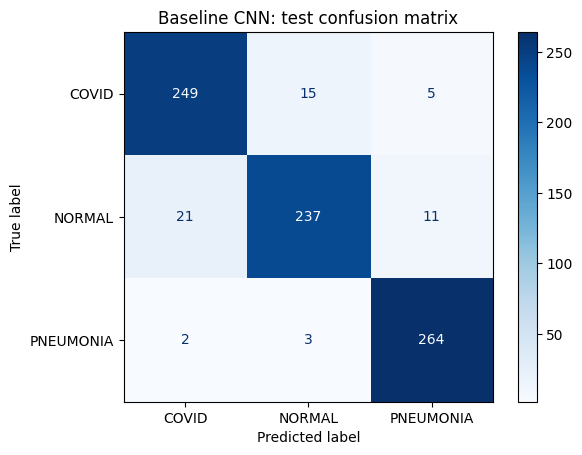

In [15]:
evaluate_model(baseline_model, 'Baseline CNN')

### Describe the Baseline

Clearly describe the architecture, loss function, optimizer, evaluation metrics, and training configuration (e.g., batch size, number of epochs) you used, and why.

1. Architecture. Four blocks of Conv2D (3 × 3, ReLU) + MaxPooling2D, with 32, 64, 128 and 128 filters, then Flatten → Dense(128, ReLU) → Dropout(0.5) → Dense(3, softmax). The model has about 2.6 M parameters. This is a simple CNN that learns small patterns first (e.g., edges) and larger ones later (e.g., lung shapes), so it is a fair baseline.
2. Loss, optimizer, metrics. Categorical cross-entropy, the standard loss for multi-class problems with one-hot labels. Adam with the default learning rate of 0.001, because it works well without much tuning. Accuracy during training, because the classes are balanced; I also report macro-F1 and the recall of each class, since missing a COVID case is the worst mistake.
3. Training. Batch size 32, up to 30 epochs, with early stopping (patience 5, best weights restored) and dropout to limit overfitting. Training stopped after 14 epochs, and the weights from epoch 9, where validation loss was lowest, were restored.
4. Results. The baseline reached 0.988 training, 0.930 validation and 0.929 test accuracy, with a test macro-F1 of 0.929. The gap of about 0.06 between training and test accuracy shows some overfitting. Viral pneumonia was the easiest class (recall 0.981) and Normal the hardest (0.881). COVID-19 recall was 0.926, so about 7% of COVID cases were missed.

---

## 3. Transfer Learning with ResNet

Use **ResNet50**, pre-trained on ImageNet, as the starting point for a new model:

1. Load ResNet50 without its top classification layer, freeze its layers, and add your own classification head. Train only the new head.
2. **Fine-tune** the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.
3. Compare its performance with the baseline CNN.

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 64s 539ms/step - accuracy: 0.7630 - loss: 0.5673 - val_accuracy: 0.8994 - val_loss: 0.2773
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.8714 - loss: 0.3201 - val_accuracy: 0.9102 - val_loss: 0.2487
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.9024 - loss: 0.2461 - val_accuracy: 0.9133 - val_loss: 0.2444
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.9144 - loss: 0.2237 - val_accuracy: 0.9303 - val_loss: 0.1970
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.9291 - loss: 0.1868 - val_accuracy: 0.9257 - val_loss: 0.1992
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.9284 - loss: 0.1924 - val_accuracy: 0.9365 - val_loss: 0.1755
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9380 - loss: 0.1635 - val_accuracy: 0.9381 - val_loss: 0.1640
Epoch 8/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9384 - loss: 0.1593 - val_accuracy: 

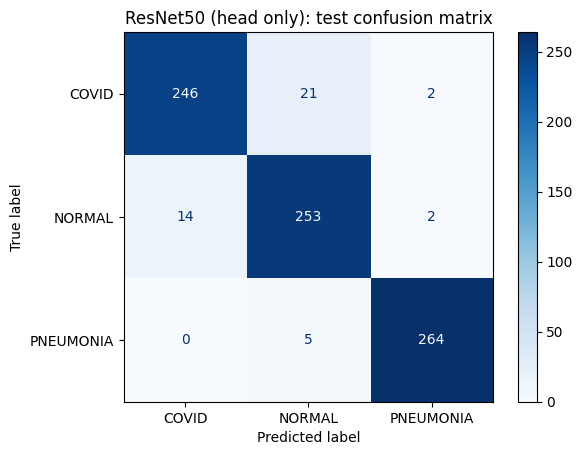

In [17]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# Note: ResNet50 expects pixel values from 0 to 255, processed with preprocess_input.
# Our images are scaled to 0–1, so multiply by 255 first. For example:
#     inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
#     x = preprocess_input(inputs * 255.0)

# Load ResNet50 with ImageNet weights and without its top layer (include_top=False), and freeze it:
resnet_base = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
resnet_base.trainable = False

# Add your own classification head (3 neurons with softmax in the last layer):
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = preprocess_input(inputs * 255.0)
x = resnet_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)
resnet_model = Model(inputs, outputs)

# Compile and train only the new head, with validation_data=(X_val, y_val):
resnet_model.compile(optimizer=Adam(),
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])
head_history = resnet_model.fit(X_train, y_train,
                                validation_data=(X_val, y_val),
                                epochs=100, batch_size=32,
                                callbacks=[early_stop()])
evaluate_model(resnet_model, 'ResNet50 (head only)')

### Fine-Tune ResNet

Unfreeze some of the top ResNet layers, recompile with a low learning rate (e.g., `1e-5`), and continue training.

In [18]:
# Unfreeze the last residual stage (conv5), but keep its BatchNorm layers frozen
resnet_base.trainable = True
for layer in resnet_base.layers:
    layer.trainable = layer.name.startswith('conv5') and not isinstance(layer, BatchNormalization)

# Recompile with a low learning rate and continue training
resnet_model.compile(optimizer=Adam(learning_rate=1e-5),
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])
ft_history = resnet_model.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              epochs=30, batch_size=32,
                              callbacks=[early_stop()])

# Join the two stages into one history for plotting
histories['ResNet50'] = {k: head_history.history[k] + ft_history.history[k] for k in head_history.history}
ft_start['ResNet50'] = len(head_history.history['loss'])

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 48s 374ms/step - accuracy: 0.9679 - loss: 0.0855 - val_accuracy: 0.9474 - val_loss: 0.1280
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 0.9857 - loss: 0.0434 - val_accuracy: 0.9520 - val_loss: 0.1332
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9915 - loss: 0.0276 - val_accuracy: 0.9350 - val_loss: 0.1894
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.9938 - loss: 0.0180 - val_accuracy: 0.9412 - val_loss: 0.1951
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.9981 - loss: 0.0121 - val_accuracy: 0.9551 - val_loss: 0.1621
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9973 - loss: 0.0087 - val_accuracy: 0.9536 - val_loss: 0.1655


### Evaluate and Compare with the Baseline

Train Acc           0.995
Val Acc             0.947
Test Acc            0.949
Test Loss           0.123
Test Macro F1       0.949
Recall COVID        0.911
Recall NORMAL       0.952
Recall PNEUMONIA    0.985
dtype: float64
              precision    recall  f1-score   support

       COVID     0.9496    0.9108    0.9298       269
      NORMAL     0.9143    0.9517    0.9326       269
   PNEUMONIA     0.9851    0.9851    0.9851       269

    accuracy                         0.9492       807
   macro avg     0.9497    0.9492    0.9492       807
weighted avg     0.9497    0.9492    0.9492       807



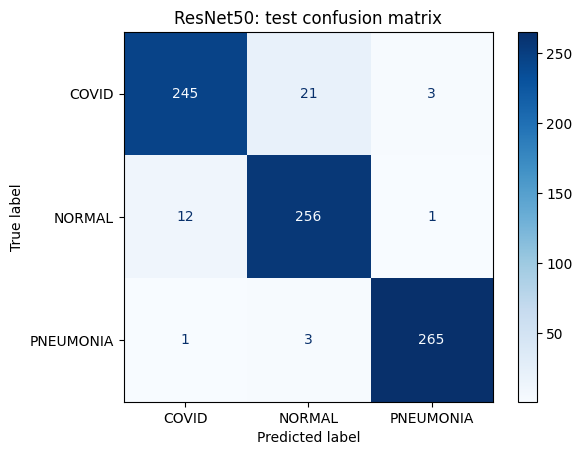

,Train Acc,Val Acc,Test Acc,Test Loss,Test Macro F1,Recall COVID,Recall NORMAL,Recall PNEUMONIA
Baseline CNN,0.988,0.930,0.929,0.207,0.929,0.926,0.881,0.981
ResNet50 (head only),0.984,0.949,0.945,0.145,0.946,0.914,0.941,0.981
ResNet50,0.995,0.947,0.949,0.123,0.949,0.911,0.952,0.985


In [19]:
evaluate_model(resnet_model, 'ResNet50')

# Baseline vs. ResNet50 (head only) vs. ResNet50 (fine-tuned)
pd.DataFrame(results).T.round(3)

### Discussion

How does the ResNet model compare with the baseline CNN? How do pre-trained features influence your model's training (e.g., speed, stability) and generalization?

1. Performance. ResNet50 did better than the baseline: 0.949 vs 0.929 test accuracy and macro-F1, and a lower test loss (0.123 vs 0.207). Most of the gain came from the pre-trained features: training only the head already gave 0.945, and fine-tuning added almost nothing (0.004). ResNet50 was much better at recognizing Normal X-rays (recall 0.952 vs 0.881), about the same on viral pneumonia (0.985 vs 0.981), and slightly worse at finding COVID cases (0.911 vs 0.926).

2. Training and generalization. Because ResNet starts from features learned on ImageNet, it reached good accuracy within a few epochs. It also overfit less: its train–test gap was 0.046, compared with 0.059 for the baseline. The improvement is modest (about 16 more correct test images out of 807), probably because ImageNet photos look very different from X-rays and the baseline already does well on this dataset.

---

## 4. Additional Architectures

Implement **three additional models** of your choice. For example, a deeper custom CNN, or pre-trained models such as VGG19, InceptionV3, MobileNetV2, DenseNet121, or EfficientNet.

Use the same `X_train`, `X_val`, and `X_test` splits and the same preprocessing for every model, so that the comparison is fair. If you use another pre-trained model, apply its own `preprocess_input` function, as in Section 3.

### Additional Model 1

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 192, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 192, 192, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 192, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 96, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 1,176,867 (4.49 MB)

 Trainable params: 1,174,947 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 73s 536ms/step - accuracy: 0.7180 - loss: 0.6840 - val_accuracy: 0.3328 - val_loss: 3.0277
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 131ms/step - accuracy: 0.8106 - loss: 0.4679 - val_accuracy: 0.3328 - val_loss: 3.1128
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - accuracy: 0.8555 - loss: 0.3482 - val_accuracy: 0.3282 - val_loss: 2.0147
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 139ms/step - accuracy: 0.8869 - loss: 0.2966 - val_accuracy: 0.3328 - val_loss: 1.4640
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 134ms/step - accuracy: 0.9043 - loss: 0.2468 - val_accuracy: 0.3359 - val_loss: 3.0550
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.9268 - loss: 0.2018 - val_accuracy: 0.3375 - val_loss: 2.9153
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.9407 - loss: 0.1539 - val_accuracy: 0.5108 - val_loss: 1.2926
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.9512 - loss: 0.1365 - val_accu

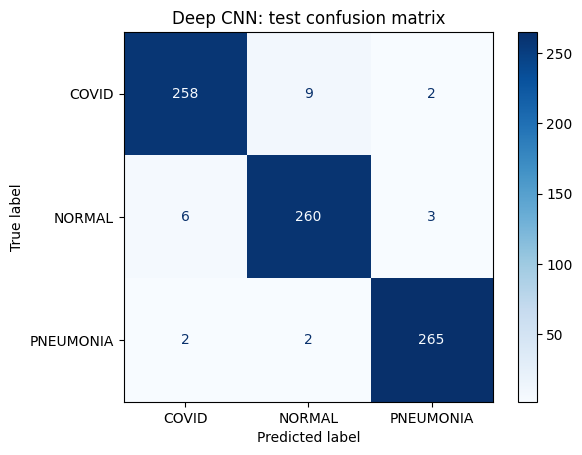

In [22]:
deep_cnn = Sequential()
deep_cnn.add(Input(shape=(IMG_SIZE, IMG_SIZE, 3)))

# Block 1: 192 x 192 x 3 -> 96 x 96 x 32
deep_cnn.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(MaxPooling2D((2, 2)))

# Block 2: 96 x 96 x 32 -> 48 x 48 x 64
deep_cnn.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(MaxPooling2D((2, 2)))

# Block 3: 48 x 48 x 64 -> 24 x 24 x 128
deep_cnn.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(MaxPooling2D((2, 2)))

# Block 4: 24 x 24 x 128 -> 12 x 12 x 256
deep_cnn.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
deep_cnn.add(BatchNormalization())
deep_cnn.add(MaxPooling2D((2, 2)))

# Classifier
deep_cnn.add(GlobalAveragePooling2D())     # 12 x 12 x 256 -> 256
deep_cnn.add(Dropout(0.4))
deep_cnn.add(Dense(3, activation='softmax'))
deep_cnn.summary()

deep_cnn.compile(optimizer=Adam(),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])
deep_history = deep_cnn.fit(X_train, y_train,
                            validation_data=(X_val, y_val),
                            epochs=50, batch_size=32,
                            callbacks=[early_stop(patience=8)])
histories['Deep CNN'] = deep_history.history
evaluate_model(deep_cnn, 'Deep CNN')

### Additional Model 2

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 66s 533ms/step - accuracy: 0.6673 - loss: 0.7782 - val_accuracy: 0.8390 - val_loss: 0.4027
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.8040 - loss: 0.4792 - val_accuracy: 0.8545 - val_loss: 0.3286
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.8323 - loss: 0.3975 - val_accuracy: 0.8793 - val_loss: 0.2926
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.8521 - loss: 0.3600 - val_accuracy: 0.8885 - val_loss: 0.2779
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.8706 - loss: 0.3224 - val_accuracy: 0.9025 - val_loss: 0.2580
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.8672 - loss: 0.3213 - val_accuracy: 0.8978 - val_loss: 0.2520
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.8737 - loss: 0.2980 - val_accuracy: 0.9056 - val_loss: 0.2461
Epoch 8/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8807 - loss: 0.2840 - val_accuracy:

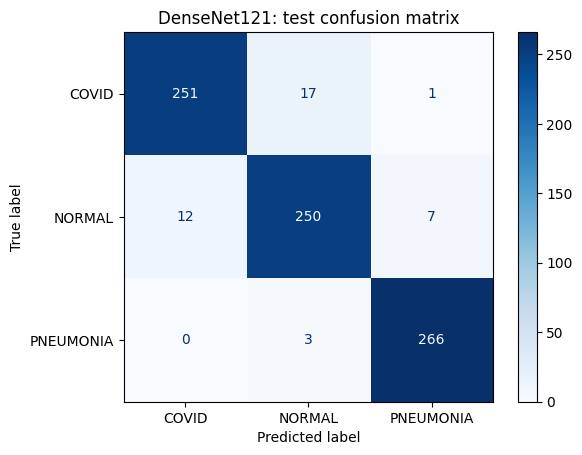

In [27]:
from tensorflow.keras.applications import DenseNet121, EfficientNetB0, densenet, efficientnet

def train_transfer(base, preprocess, name, n_unfreeze):
    """Two-stage transfer learning"""
    base.trainable = False
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = preprocess(inputs * 255.0)
    x = base(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(3, activation='softmax')(x)
    model = Model(inputs, outputs)

    # Stage 1: train the head only
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    h1 = model.fit(X_train, y_train,
                   validation_data=(X_val, y_val),
                   epochs=100, batch_size=32,
                   callbacks=[early_stop()])

    # Stage 2: unfreeze the last n_unfreeze layers and fine-tune
    base.trainable = True
    for layer in base.layers[:-n_unfreeze]:
        layer.trainable = False
    for layer in base.layers[-n_unfreeze:]:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    h2 = model.fit(X_train, y_train,
                   validation_data=(X_val, y_val),
                   epochs=100, batch_size=32,
                   callbacks=[early_stop()])

    histories[name] = {k: h1.history[k] + h2.history[k] for k in h1.history}
    ft_start[name] = len(h1.history['loss'])
    return model

densenet_base = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
densenet_model = train_transfer(densenet_base, densenet.preprocess_input, 'DenseNet121', n_unfreeze=60)
evaluate_model(densenet_model, 'DenseNet121')

### Additional Model 3

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 123s 972ms/step - accuracy: 0.7657 - loss: 0.5734 - val_accuracy: 0.8607 - val_loss: 0.3521
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8470 - loss: 0.3777 - val_accuracy: 0.8839 - val_loss: 0.2961
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.8706 - loss: 0.3293 - val_accuracy: 0.8947 - val_loss: 0.2627
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.8881 - loss: 0.2877 - val_accuracy: 0.9040 - val_loss: 0.2407
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8981 - loss: 0.2629 - val_accuracy: 0.9087 - val_loss: 0.2303
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9032 - loss: 0.2576 - val_accuracy: 0.9118 - val_loss: 0.2198
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.9070 - loss: 0.2396 - val_accuracy: 0.9180 - val_loss: 0.2110
Epoch 8/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9129 - loss: 0.2262 - val_accuracy:

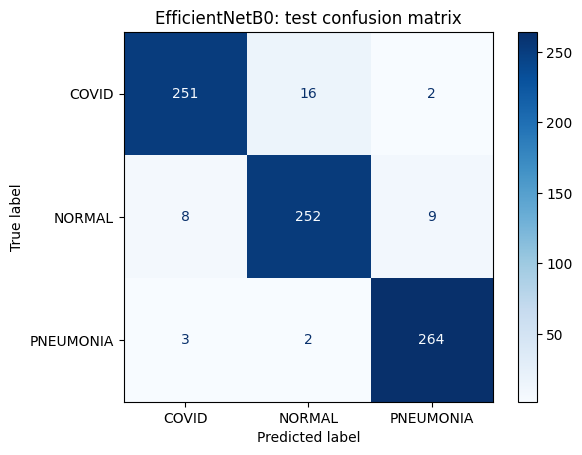

In [29]:
effnet_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
effnet_model = train_transfer(effnet_base, efficientnet.preprocess_input, 'EfficientNetB0', n_unfreeze=30)
evaluate_model(effnet_model, 'EfficientNetB0')

### Describe Your Models

For each of the three models, briefly describe its architecture and why you chose it.

Model 1: Deeper CNN. Four blocks, each with two Conv2D layers and BatchNormalization, followed by max pooling (32, 64, 128 and 256 filters). Then global average pooling, Dropout(0.4) and Dense(3, softmax), about 1.2 M parameters in total. I chose it to see whether a better design helps without pre-training. Two conv layers per block can learn more complex patterns, BatchNorm speeds up training, and global average pooling replaces Flatten, so the classifier has far fewer parameters and should overfit less. It reached 0.970 test accuracy, the best so far, but its validation accuracy jumped around a lot in the first 14 epochs.

Model 2: DenseNet121. In DenseNet, each layer receives the outputs of all earlier layers in its block, so features are reused and the model stays small (about 7 M parameters). I used the same head and two-stage training as ResNet50 and fine-tuned the last 60 layers. I chose it because it is one of the most common models for chest X-rays (for example, CheXNet). It reached 0.950 test accuracy.

Model 3: EfficientNetB0. A small, efficient model (about 4 M parameters) that balances network depth, width and image size. Same head and two-stage training, fine-tuning the last 30 layers. I chose it to see whether a lightweight model, one that could run on an ordinary computer, can match the bigger ones. It also reached 0.950 test accuracy.

---

## 5. Performance Comparison

### Test Performance of All Models

Evaluate **every model** (the baseline, ResNet, and your three additional models) on the same test set. Present the results in a table, and **highlight the model with the best test performance**.

In [31]:
main_models = ['Baseline CNN', 'ResNet50', 'Deep CNN', 'DenseNet121', 'EfficientNetB0']
table = pd.DataFrame(results).T.loc[main_models].sort_values('Test Acc', ascending=False)

best = table['Test Acc'].idxmax()
print('Best model on the test set:', best)

# Highlight the row of the best model
table.style.format('{:.3f}').apply(
    lambda row: ['background-color: green' if row.name == best else '' for _ in row], axis=1)

Best model on the test set: Deep CNN


,Train Acc,Val Acc,Test Acc,Test Loss,Test Macro F1,Recall COVID,Recall NORMAL,Recall PNEUMONIA
Deep CNN,1.000,0.975,0.970,0.108,0.970,0.959,0.967,0.985
EfficientNetB0,0.991,0.955,0.950,0.114,0.950,0.933,0.937,0.981
DenseNet121,0.995,0.946,0.950,0.129,0.950,0.933,0.929,0.989
ResNet50,0.995,0.947,0.949,0.123,0.949,0.911,0.952,0.985
Baseline CNN,0.988,0.930,0.929,0.207,0.929,0.926,0.881,0.981


### Hyperparameters and Training Strategies

Summarize the key hyperparameters and training strategies of each model in a table (e.g., learning rate, batch size, number of epochs, optimizer).

All models use the same data, input size (192 × 192), loss (categorical cross-entropy), optimizer (Adam), batch size (32), and early stopping on validation loss with the best weights restored.

| Model | Pre-trained | What is trained | Learning rate | Max epochs (actually run) | Patience | Regularization |
|---|---|---|---|---|---|---|
| Baseline CNN | No | All layers | 1e-3 | 30 (14) | 5 | Dropout 0.5 |
| ResNet50 | ImageNet | Head, then `conv5` stage | 1e-3 → 1e-5 | 100 + 30 (27 + 6) | 5 | Dropout 0.3, frozen BatchNorm |
| Deep CNN | No | All layers | 1e-3 | 50 (31) | 8 | BatchNorm, GAP, Dropout 0.4 |
| DenseNet121 | ImageNet | Head, then last 60 layers | 1e-3 → 1e-5 | 100 + 100 (43 + 27) | 5 | Dropout 0.3, frozen BatchNorm |
| EfficientNetB0 | ImageNet | Head, then last 30 layers | 1e-3 → 1e-5 | 100 + 100 (49 + 18) | 5 | Dropout 0.3, frozen BatchNorm |

The from-scratch models are trained end to end. The pre-trained models use two-stage transfer learning: first only the new head is trained, then the top layers are unfrozen and trained with a 100 times smaller learning rate so the ImageNet features adapt to X-rays without being destroyed. The max epochs are only upper limits; early stopping decided when each model stopped.

### Training Curves

Plot the training and validation **loss** and **accuracy** over epochs for each model.

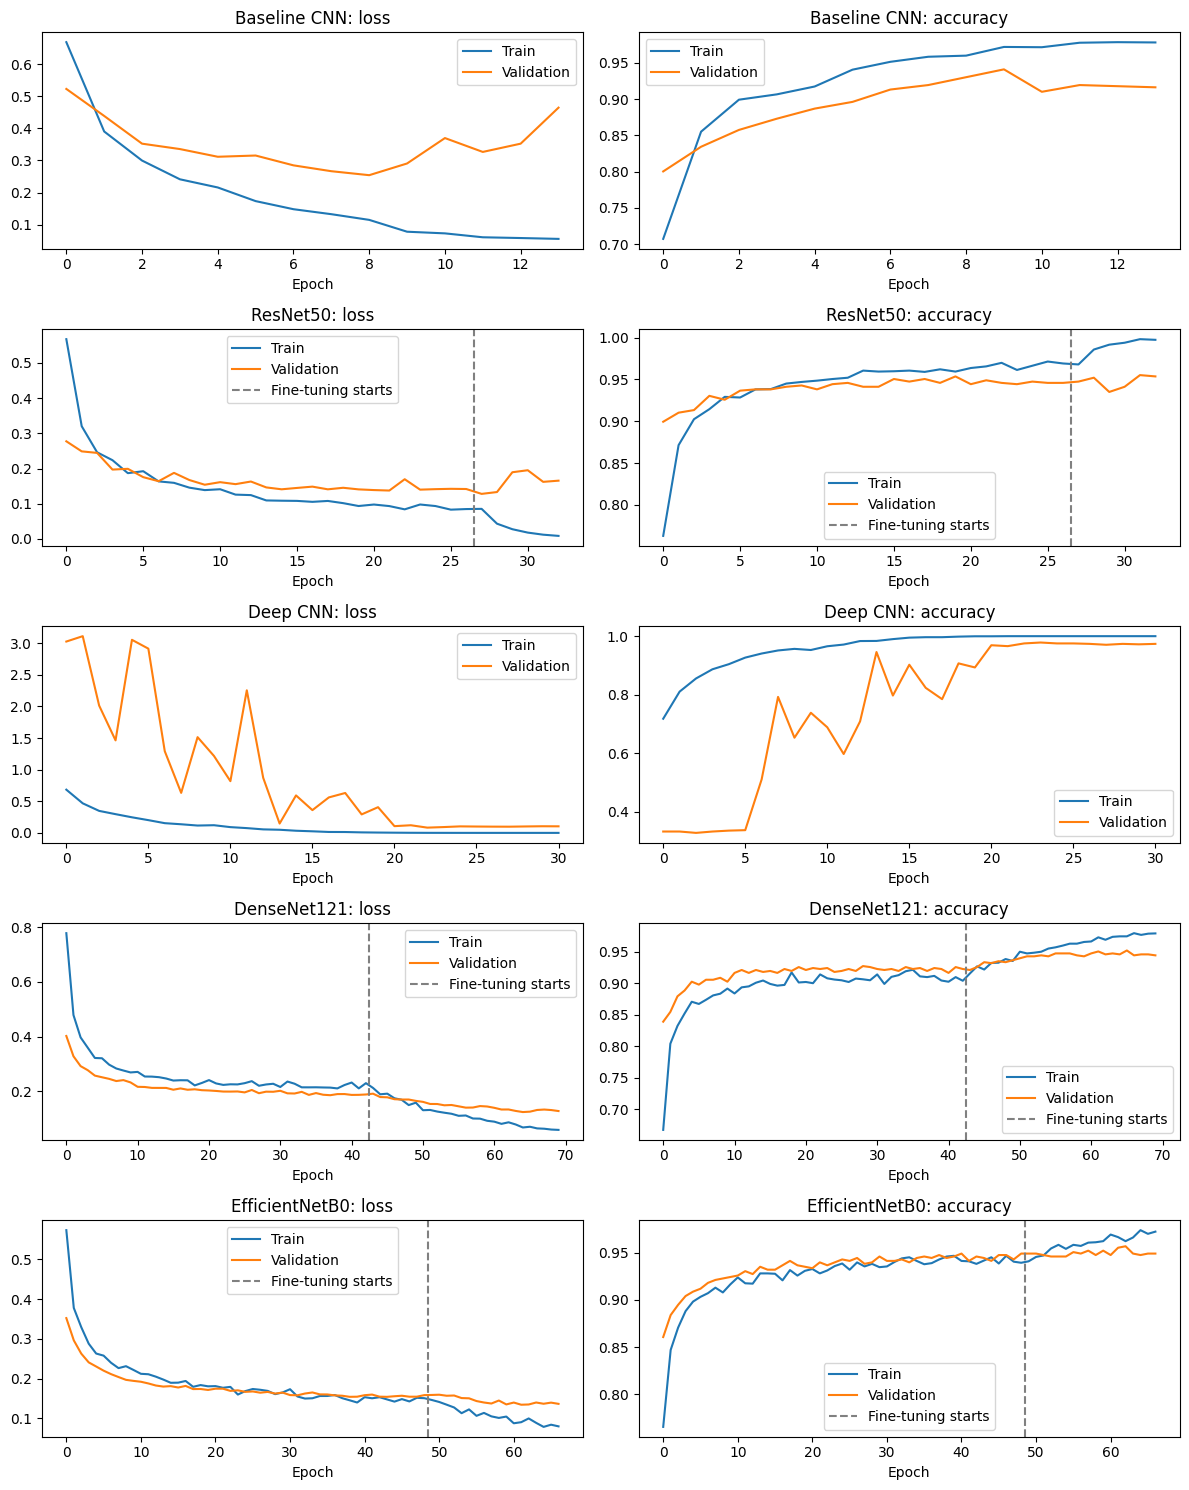

In [32]:
fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3 * len(histories)))
for row, (name, h) in enumerate(histories.items()):
    for col, metric in enumerate(['loss', 'accuracy']):
        ax = axes[row, col]
        ax.plot(h[metric], label='Train')
        ax.plot(h['val_' + metric], label='Validation')
        if name in ft_start:                  # mark where fine-tuning starts
            ax.axvline(ft_start[name] - 0.5, color='gray', linestyle='--', label='Fine-tuning starts')
        ax.set_title(f'{name}: {metric}')
        ax.set_xlabel('Epoch')
        ax.legend()
plt.tight_layout()
plt.show()

---

## 6. Augmentation

Re-train **at least one** of your models using **data augmentation** (e.g., flipping, rotation, zoom, cropping, contrast changes), and compare its performance with the same model trained without augmentation.

> **Tip:** Keras augmentation layers such as `layers.RandomFlip`, `layers.RandomRotation`, `layers.RandomZoom`, and `layers.RandomContrast` can be added at the start of a model. They only change images during training. Think about which augmentations make sense for chest X-rays.

Epoch 1/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 38s 320ms/step - accuracy: 0.6770 - loss: 0.7504 - val_accuracy: 0.3328 - val_loss: 6.2920
Epoch 2/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 224ms/step - accuracy: 0.7723 - loss: 0.5132 - val_accuracy: 0.3328 - val_loss: 4.8510
Epoch 3/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 221ms/step - accuracy: 0.8087 - loss: 0.4586 - val_accuracy: 0.3282 - val_loss: 1.2108
Epoch 4/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 223ms/step - accuracy: 0.8141 - loss: 0.4309 - val_accuracy: 0.3328 - val_loss: 2.2565
Epoch 5/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 226ms/step - accuracy: 0.8362 - loss: 0.3841 - val_accuracy: 0.5650 - val_loss: 1.0235
Epoch 6/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 228ms/step - accuracy: 0.8486 - loss: 0.3576 - val_accuracy: 0.4659 - val_loss: 1.2096
Epoch 7/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 222ms/step - accuracy: 0.8610 - loss: 0.3474 - val_accuracy: 0.4938 - val_loss: 2.4104
Epoch 8/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 227ms/step - accuracy: 0.8772 - loss: 0.3045 - val_accu

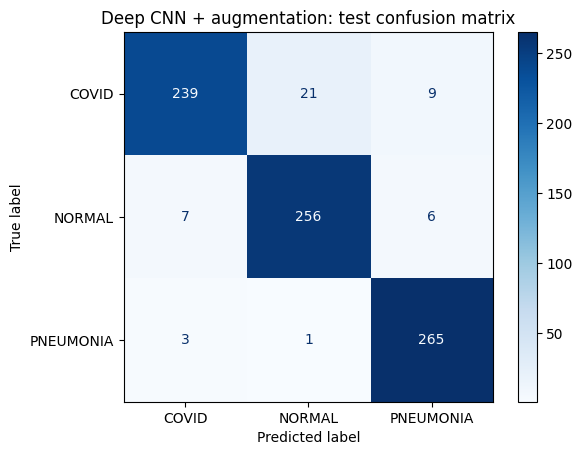

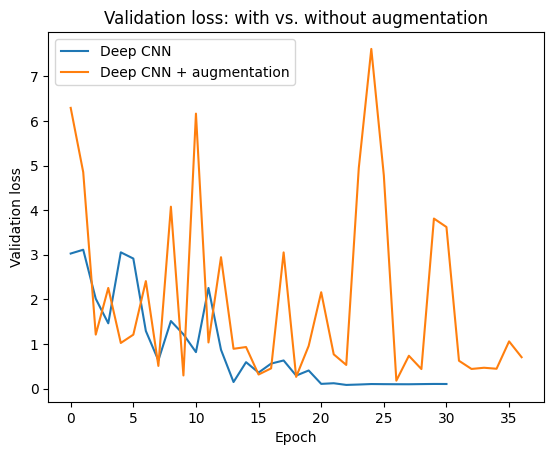

,Train Acc,Val Acc,Test Acc,Test Loss,Test Macro F1,Recall COVID,Recall NORMAL,Recall PNEUMONIA
Deep CNN,1.000,0.975,0.970,0.108,0.970,0.959,0.967,0.985
Deep CNN + augmentation,0.962,0.940,0.942,0.161,0.941,0.888,0.952,0.985


In [35]:
data_augmentation = Sequential([
    layers.RandomRotation(0.03, fill_mode='constant'),             # about +/- 11 degrees
    layers.RandomZoom(0.1, fill_mode='constant'),                  # +/- 10% zoom
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant'),    # +/- 5% shift
    layers.RandomContrast(0.15),                                   # +/- 15% contrast
])

# Same architecture as the Deep CNN in Section 4, with augmentation in front
aug_model = Sequential()
aug_model.add(Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
aug_model.add(data_augmentation)

# Block 1: 192 x 192 x 3 -> 96 x 96 x 32
aug_model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(MaxPooling2D((2, 2)))

# Block 2: 96 x 96 x 32 -> 48 x 48 x 64
aug_model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(MaxPooling2D((2, 2)))

# Block 3: 48 x 48 x 64 -> 24 x 24 x 128
aug_model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(MaxPooling2D((2, 2)))

# Block 4: 24 x 24 x 128 -> 12 x 12 x 256
aug_model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
aug_model.add(BatchNormalization())
aug_model.add(MaxPooling2D((2, 2)))

# Classifier
aug_model.add(GlobalAveragePooling2D())              # 12 x 12 x 256 -> 256
aug_model.add(Dropout(0.4))
aug_model.add(Dense(3, activation='softmax'))

aug_model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
aug_history = aug_model.fit(X_train, y_train,
                            validation_data=(X_val, y_val),
                            epochs=80, batch_size=32,
                            callbacks=[early_stop(patience=10)])
histories['Deep CNN + augmentation'] = aug_history.history
evaluate_model(aug_model, 'Deep CNN + augmentation')

# Compare validation loss with and without augmentation
for name in ['Deep CNN', 'Deep CNN + augmentation']:
    plt.plot(histories[name]['val_loss'], label=name)
plt.title('Validation loss: with vs. without augmentation')
plt.xlabel('Epoch')
plt.ylabel('Validation loss')
plt.legend()
plt.show()

# Compare test results with and without augmentation
display(pd.DataFrame(results).T.loc[['Deep CNN', 'Deep CNN + augmentation']].round(3))

Describe the augmentations you used and why you chose them. How did they affect performance?

1. Augmentations and why. I used small rotations (about ±11°), zoom (±10%), shifts (±5%) and contrast changes (±15%). These match real differences between X-rays: patients lean slightly, stand at different distances, and machines use different exposure settings. I did **not** use flips. An upside-down chest X-ray never happens, and a left-right flip puts the heart on the wrong side. I added the augmentation in front of the Deep CNN (my best model) and kept everything else the same.

2. Effect on performance. Augmentation reduced overfitting: training accuracy dropped from 1.000 to 0.962, because the model sees slightly different images every epoch and cannot just memorize them, and the train–test gap shrank from 0.030 to 0.020. But test performance got worse (0.942 vs 0.970 accuracy), and COVID recall dropped the most (0.888 vs 0.959). Augmentation also did not fix the unstable training: validation accuracy still jumped between about 0.33 and 0.94, and each epoch took longer (about 18 s vs 11 s). I think there are three reasons. First, augmentation makes the task harder, so the model needs more training, and early stopping (best epoch 27) may have stopped it before it settled. Second, the test images come from the same sources as the training images, so the model gains little from learning to handle variations the test set does not contain. Third, the Deep CNN's results vary a lot between runs (an earlier run without augmentation got only 0.911), so part of this difference may be random. Augmentation might still help on X-rays from other hospitals, which this test set cannot measure.

---

## 7. Interpretability and Insights

Conclude your project:

- **Which model performed best, and why?** Support your reasoning with performance metrics and training curves.
- **What is the practical utility of your best-performing model?**
  - Who would benefit from using this model?
  - In what types of real-world scenarios would your solution be useful?

1. Which model performed best, and why

   The Deep CNN performed best, with 0.970 test accuracy, 0.970 macro-F1, the lowest test loss (0.108) and the highest COVID-19 recall (0.959). The three pre-trained models came next at about 0.950 (DenseNet121 0.950, EfficientNetB0 0.950, ResNet50 0.949), and the baseline CNN was last at 0.929.

   I think it worked best for two reasons. First, it learned all its features directly from chest X-rays, while the pre-trained models start from features learned on color photos (ImageNet), which look very different from X-rays. Second, BatchNorm and global average pooling let it go deeper than the baseline with fewer parameters (1.2 M vs 2.6 M), so it learned more detailed patterns without overfitting badly.

   The training curves add an important caveat. The Deep CNN's validation accuracy jumped between about 0.33 and 0.95 for the first 20 epochs before it settled near 0.97, and an earlier run of the same model reached only 0.911. The pre-trained models had smooth, stable curves and landed at about 0.95 every time. The gap between the Deep CNN and the next model is only about 16 of 807 test images. So the Deep CNN gave the best result here, but the pre-trained models are more reliable, and I would want to repeat the training several times before trusting the ranking.

2. What is the practical utility of the best model

- Who would benefit: radiologists and emergency departments that need to decide which X-rays to read first, small or rural clinics that have an X-ray machine but no radiologist, and public health teams that need to screen many people quickly when COVID tests are scarce.
- Real-world scenarios: (1) triage during an outbreak, so likely COVID-19 cases are read and isolated first; (2) a quick second opinion for a busy or less experienced doctor; (3) screening at scale where specialists are scarce. Because the Deep CNN is small (1.2 M parameters), it could run on an ordinary computer without a GPU.

3. Limitations.
   The model still misses about 4% of COVID cases, and the classes in this dataset come from different hospitals (the viral pneumonia images are from children), so the model may partly rely on these differences instead of the disease itself. Before any real use, it would need testing on X-rays from new hospitals, a check with a tool like Grad-CAM to make sure it looks at the lungs, and a doctor making the final decision.